# Notebook 1: Sampling, Data Cleaning and EDA

HCLTech Future Ready Data Science Hackathon, Use case 4: IT Support Ticket Classification and Analytics

The project goal is to predict the category of an IT support ticket from the message the customer writes,
and to build a dashboard that shows categories, trends, recurring issues and problem areas.

The full project runs in six notebooks:

| Notebook | What it does |
|---|---|
| **01 (this one)** | Take a 20,000-ticket sample, check quality, clean, explore |
| 02 | Train and compare classifiers (Logistic Regression, SVM, Naive Bayes) |
| 03 | Explain the model with SHAP |
| 04 | Find recurring issues with clustering |
| 05 | Detect anomalies |
| 06 | GenAI assistant (RAG) that answers questions about the results |

Before building any model, we want to understand the data properly: what is in it, what is wrong with it,
what is related to what, and what could mislead a model.

What this notebook covers:

1. Taking the sample, loading the data and understanding the columns
2. Data quality checks
3. Cleaning
4. Univariate analysis (one column at a time)
5. Class imbalance
6. Bivariate analysis (two columns at a time)
7. Correlation analysis
8. Data leakage
9. Summary

The raw file goes in `data/raw/`. Outputs are written to `data/processed/` and charts to `reports/figures/`.

## 1. Load the data and take a sample

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sys
from sklearn.model_selection import train_test_split

sys.path.append("..")
from src import config

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", "{:.2f}".format)

OUT_DIR = config.FIGURES          # charts go here
TARGET = config.TARGET
TEXT = config.TEXT

In [2]:
full = pd.read_excel(config.RAW_FILE)
print("Full dataset:", full.shape[0], "rows,", full.shape[1], "columns")

Full dataset: 100000 rows, 20 columns


The full file has 100,000 tickets. We work with a sample of **20,000** to keep everything fast and easy to rerun.

The sample is **stratified** by `issue_type`, which means each category keeps the same share it has in the full data.
A fixed random seed (42) means anyone running this gets exactly the same 20,000 tickets.

In [3]:
df, _ = train_test_split(full, train_size=config.SAMPLE_SIZE, stratify=full[TARGET], random_state=config.SEED)
df = df.reset_index(drop=True)

# check the sample looks like the full data
compare = pd.DataFrame({
    "full_%": full[TARGET].value_counts(normalize=True) * 100,
    "sample_%": df[TARGET].value_counts(normalize=True) * 100,
})
print("Sample:", df.shape[0], "rows")
print("Unique messages in full data:", full[TEXT].nunique(), "| in sample:", df[TEXT].nunique())
compare

Sample: 20000 rows
Unique messages in full data: 96 | in sample: 96


,full_%,sample_%
issue_type,,
how_to,12.74,12.74
account_access,12.61,12.61
performance,12.51,12.52
feature_request,12.49,12.48
other,12.46,12.46
security_concern,12.46,12.46
billing_problem,12.38,12.38
bug,12.35,12.35


The category shares match the full data almost exactly, and all the different messages are still present in the sample.

In [4]:
df.head()

,ticket_id,created_at,customer_id,customer_segment,channel,product_area,issue_type,priority,status,sla_plan,initial_message,agent_first_reply,resolution_summary,resolution_time_hours,reopened,customer_sentiment,csat_score,has_attachment,platform,region
0,TCKT_077009,2023-05-29T07:09:19,CUST_02907,education,chat,analytics_dashboard,other,medium,in_progress,platinum,I have a general question about my account.,Thanks for contacting support. Our team is reviewing this and will follow up within 24 hours.,NaN,NaN,0,neutral,0,0,ios,APAC
1,TCKT_052709,2022-05-10T00:54:03,CUST_08223,small_business,in_app,billing,other,low,on_hold,standard,I need help but I'm not sure which category this fits in.,Thanks for contacting support. We will look into this and get back to you within the next 48 hours.,NaN,NaN,1,neutral,0,0,desktop_app,LATAM
2,TCKT_078531,2025-12-24T22:19:38,CUST_01937,education,chat,api_integration,feature_request,low,in_progress,standard,It would be great to have api integration support in your product.,Thanks for your feature suggestion. We will look into this and get back to you within the next 48 hours.,NaN,NaN,0,neutral,4,0,ios,MEA
3,TCKT_036435,2023-04-27T20:57:00,CUST_01938,education,chat,notifications,other,medium,resolved,standard,I need help but I'm not sure which category this fits in.,Thanks for contacting support. Our team is reviewing this and will follow up within 24 hours.,Provided general guidance and confirmed the issue was resolved.,38.66,0,neutral,0,1,api_client,LATAM
4,TCKT_009100,2024-08-21T23:44:41,CUST_00497,individual,chat,analytics_dashboard,security_concern,low,open,standard,I noticed a suspicious login on my account.,We take security very seriously. We will look into this and get back to you within the next 48 hours.,NaN,NaN,0,neutral,4,1,android,LATAM


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ticket_id              20000 non-null  str    
 1   created_at             20000 non-null  str    
 2   customer_id            20000 non-null  str    
 3   customer_segment       20000 non-null  str    
 4   channel                20000 non-null  str    
 5   product_area           20000 non-null  str    
 6   issue_type             20000 non-null  str    
 7   priority               20000 non-null  str    
 8   status                 20000 non-null  str    
 9   sla_plan               20000 non-null  str    
 10  initial_message        20000 non-null  str    
 11  agent_first_reply      20000 non-null  str    
 12  resolution_summary     12160 non-null  str    
 13  resolution_time_hours  12160 non-null  float64
 14  reopened               20000 non-null  int64  
 15  customer_sent

### What each column means

Some columns are available the moment a ticket is created. Others only get filled in after an agent has worked on it.
This difference matters a lot later, because a model can only use what is known when a new ticket arrives.

| Column | Meaning | Group |
|---|---|---|
| ticket_id, customer_id | Identifiers | ID |
| initial_message | What the customer wrote | Input text |
| issue_type | Ticket category | Target |
| created_at, priority, channel, product_area, platform, region, customer_segment, sla_plan, has_attachment | Ticket details | Known at arrival |
| status, agent_first_reply, resolution_summary, resolution_time_hours, reopened, customer_sentiment, csat_score | What happened afterwards | Known only later |

In [6]:
ID_COLS = ["ticket_id", "customer_id"]
ARRIVAL_COLS = ["created_at", "priority", "channel", "product_area", "platform", "region",
                "customer_segment", "sla_plan", "has_attachment"]
LATER_COLS = ["status", "agent_first_reply", "resolution_summary", "resolution_time_hours",
              "reopened", "customer_sentiment", "csat_score"]

# quick check that we have not missed or misspelt any column
grouped = ID_COLS + [TEXT, TARGET] + ARRIVAL_COLS + LATER_COLS
print("Columns not in any group:", set(df.columns) - set(grouped))
print("Group names not in data :", set(grouped) - set(df.columns))

Columns not in any group: set()
Group names not in data : set()


## 2. Data quality checks

### 2.1 Missing values

In [7]:
missing = pd.DataFrame({"missing": df.isna().sum(), "percent": df.isna().mean() * 100})
missing[missing["missing"] > 0]

,missing,percent
resolution_summary,7840,39.20
resolution_time_hours,7840,39.20
region,3995,19.98


Three columns have gaps. Before filling anything, let's see why they are empty.

In [8]:
# are the resolution columns empty only for tickets that are not finished?
pd.crosstab(df["status"], df["resolution_time_hours"].isna(), colnames=["resolution time missing"])

resolution time missing,False,True
status,,
closed_no_action,2041,0
in_progress,0,3884
on_hold,0,2081
open,0,1875
resolved,10119,0


In [9]:
# is region missing more often in some channels? if the share is the same everywhere, it is random
df.groupby("channel")["region"].apply(lambda s: s.isna().mean()).rename("share missing")

channel
chat               0.21
email              0.20
in_app             0.20
phone_transcript   0.20
web_form           0.19
Name: share missing, dtype: float64

The resolution columns are empty only for tickets that are open, in progress or on hold. Those tickets simply
haven't been resolved yet, so the gaps are expected and we leave them empty. Filling them would mean inventing data.

Region is missing for about 20% of tickets, and the share is the same in every channel, so it looks random.
We'll label these as "Unknown" so they still show up in filters.

### 2.2 Duplicates

In [10]:
print("Duplicate rows             :", df.duplicated().sum())
print("Duplicate ticket IDs       :", df["ticket_id"].duplicated().sum())
print("Duplicate rows (ignore ID) :", df.drop(columns="ticket_id").duplicated().sum())
print("Unique message texts       :", df[TEXT].nunique(), "out of", len(df))

Duplicate rows             : 0
Duplicate ticket IDs       : 0
Duplicate rows (ignore ID) : 0
Unique message texts       : 96 out of 20000


There are no duplicate tickets. The messages, though, repeat a lot: 20,000 tickets use only 96 different sentences.
The tickets themselves are still different (different customers, dates and priorities), so we keep all rows.
We'll come back to this in the data leakage section, because it changes how we have to split the data.

### 2.3 Values and ranges

In [11]:
df.nunique().sort_values().to_frame("unique values")

,unique values
reopened,2
has_attachment,2
sla_plan,3
priority,4
region,4
customer_sentiment,5
status,5
customer_segment,5
channel,5
platform,5


In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
resolution_time_hours,12160.00,44.66,49.21,0.11,14.47,29.48,51.02,239.94
reopened,20000.00,0.05,0.22,0.00,0.00,0.00,0.00,1.00
csat_score,20000.00,2.26,1.78,0.00,0.00,2.00,4.00,5.00
has_attachment,20000.00,0.25,0.43,0.00,0.00,0.00,0.00,1.00


In [13]:
print("Resolution time <= 0 :", (df["resolution_time_hours"] <= 0).sum())
print("reopened values      :", sorted(df["reopened"].unique()))
print("has_attachment values:", sorted(df["has_attachment"].unique()))
print("csat_score values    :", sorted(df["csat_score"].unique()))
print("csat_score = 0       :", (df["csat_score"] == 0).sum())

Resolution time <= 0 : 0
reopened values      : [np.int64(0), np.int64(1)]
has_attachment values: [np.int64(0), np.int64(1)]
csat_score values    : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
csat_score = 0       : 5944


CSAT is a satisfaction score from 1 to 5, yet about 30% of tickets have a 0. Is that a very unhappy customer,
or a customer who never answered the survey? Comparing it with sentiment should tell us.

In [14]:
pd.crosstab(df["customer_sentiment"], df["csat_score"])

csat_score,0,1,2,3,4,5
customer_sentiment,,,,,,
negative,1594,0,1814,1778,0,0
neutral,1926,0,0,2282,2392,0
positive,936,0,0,0,1150,1125
very_negative,958,1170,1099,0,0,0
very_positive,530,0,0,0,0,1246


Scores 1 to 5 line up neatly with sentiment (very negative customers give 1 or 2, very positive ones give 5).
A score of 0 shows up for every sentiment, including very positive. So 0 means "not rated", and we'll treat it as missing.
If we left it in, the average CSAT would look much worse than it really is.

### 2.4 Dates and text

In [15]:
dates = pd.to_datetime(df["created_at"], errors="coerce")
print("Unreadable dates:", dates.isna().sum())
print("Date range      :", dates.min(), "to", dates.max())
print("Empty messages  :", (df[TEXT].str.strip() == "").sum())
print("Message length  :", df[TEXT].str.len().min(), "to", df[TEXT].str.len().max(), "characters")

Unreadable dates: 0
Date range      : 2022-01-01 00:31:35 to 2025-12-30 17:26:40
Empty messages  : 0
Message length  : 43 to 79 characters


### Quality check summary

| Check | What we found | What we do |
|---|---|---|
| Missing resolution fields | Only for unfinished tickets | Leave empty |
| Missing region (20%) | Random | Fill with "Unknown" |
| Duplicate rows or IDs | None | Nothing |
| Repeated messages | Only 96 unique texts | Keep rows, handle when splitting |
| csat_score = 0 | Means "not rated" | Set to missing |
| Bad numbers, bad dates, empty text | None | Nothing |
| customer_id | Personal identifier, not useful here | Drop |

## 3. Cleaning

In [16]:
clean = df.copy()

clean["created_at"] = pd.to_datetime(clean["created_at"])          # text -> real dates
clean["region"] = clean["region"].fillna("Unknown")                 # missing at random
clean["csat_score"] = clean["csat_score"].replace(0, np.nan)        # 0 = not rated
clean[TEXT] = clean[TEXT].str.strip().str.replace(r"\s+", " ", regex=True)   # tidy spaces
clean = clean.drop(columns=["customer_id"])                          # not needed

print("Shape after cleaning:", clean.shape)

Shape after cleaning: (20000, 19)


A few extra columns make the analysis easier to read. They are only for exploring; section 8 decides what a model is allowed to use.

In [17]:
clean["word_count"] = clean[TEXT].str.split().str.len()
clean["year"] = clean["created_at"].dt.year
clean["month"] = clean["created_at"].dt.to_period("M").dt.to_timestamp()
clean["weekday"] = clean["created_at"].dt.day_name()
clean["hour"] = clean["created_at"].dt.hour
clean["is_negative"] = clean["customer_sentiment"].isin(["negative", "very_negative"]).astype(int)
clean["priority_rank"] = clean["priority"].map({"low": 0, "medium": 1, "high": 2, "urgent": 3})
clean["sentiment_score"] = clean["customer_sentiment"].map(
    {"very_negative": -2, "negative": -1, "neutral": 0, "positive": 1, "very_positive": 2})

clean[[TEXT, "word_count", "weekday", "hour", "priority_rank", "sentiment_score"]].head()

,initial_message,word_count,weekday,hour,priority_rank,sentiment_score
0,I have a general question about my account.,8,Monday,7,1,0
1,I need help but I'm not sure which category this fits in.,12,Tuesday,0,0,0
2,It would be great to have api integration support in your product.,12,Wednesday,22,0,0
3,I need help but I'm not sure which category this fits in.,12,Thursday,20,1,0
4,I noticed a suspicious login on my account.,8,Wednesday,23,0,0


In [18]:
# make sure the cleaning did what we wanted
print("Missing region left        :", clean["region"].isna().sum())
print("csat_score = 0 left        :", (clean["csat_score"] == 0).sum())
print("Tickets with a CSAT rating :", clean["csat_score"].notna().sum())
print("Unfinished tickets (no resolution time):", clean["resolution_time_hours"].isna().sum())

Missing region left        : 0
csat_score = 0 left        : 0
Tickets with a CSAT rating : 14056
Unfinished tickets (no resolution time): 7840


## 4. Univariate analysis

Here we look at one column at a time to see what values it takes and how they are spread.

### 4.1 The target: issue_type

                  tickets  percent
issue_type                        
how_to               2548    12.74
account_access       2522    12.61
performance          2503    12.52
feature_request      2497    12.48
other                2492    12.46
security_concern     2492    12.46
billing_problem      2476    12.38
bug                  2470    12.35


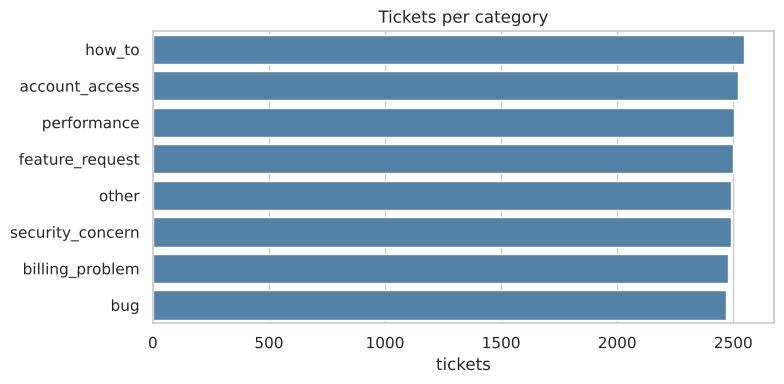

In [19]:
counts = clean[TARGET].value_counts()
print(pd.DataFrame({"tickets": counts, "percent": counts / len(clean) * 100}))

plt.figure(figsize=(8, 4))
sns.countplot(data=clean, y=TARGET, order=counts.index, color="steelblue")
plt.title("Tickets per category")
plt.xlabel("tickets"); plt.ylabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_target.png"); plt.show()

Eight categories, each with roughly 12.5% of the tickets. Section 5 looks at balance in more detail.

### 4.2 Categorical columns

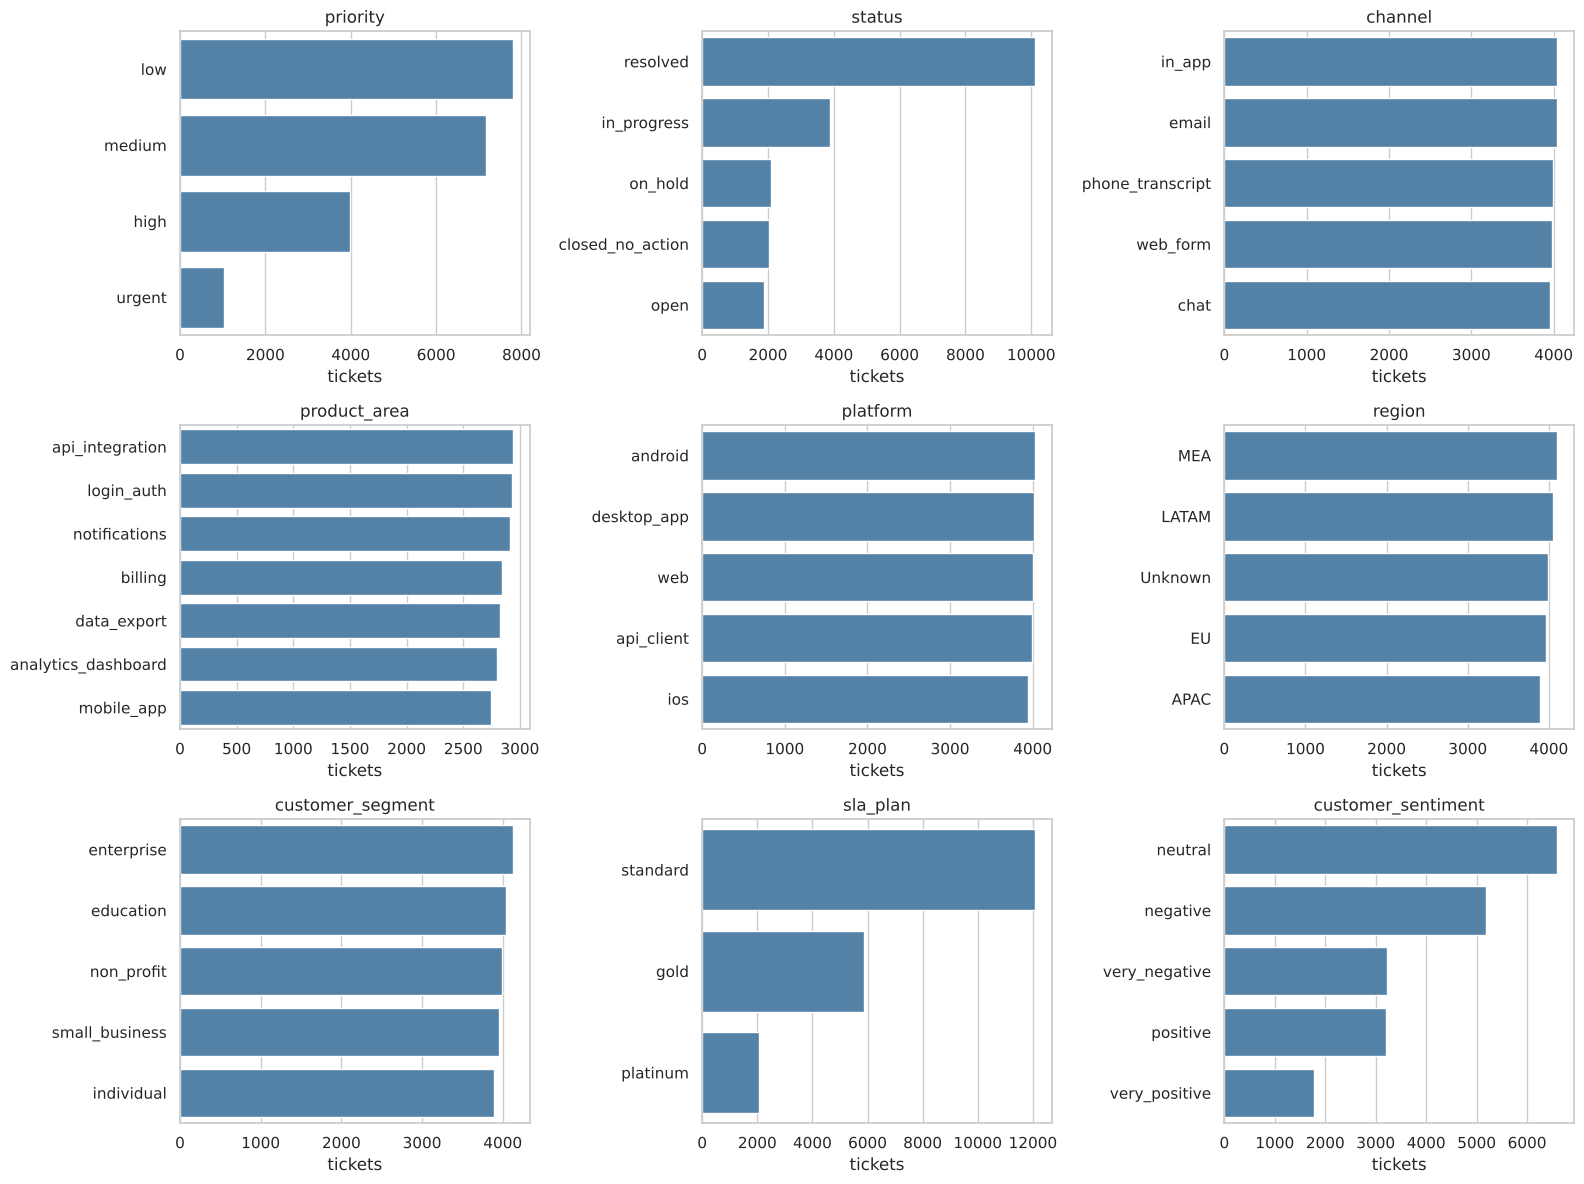

In [20]:
cat_cols = ["priority", "status", "channel", "product_area", "platform", "region",
            "customer_segment", "sla_plan", "customer_sentiment"]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(data=clean, y=col, order=clean[col].value_counts().index, color="steelblue", ax=ax)
    ax.set_title(col); ax.set_xlabel("tickets"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/02_categorical.png"); plt.show()

In [21]:
for col in ["priority", "status", "customer_sentiment"]:
    print(clean[col].value_counts(normalize=True).mul(100).round(1).to_string(), "\n")

priority
low      39.00
medium   35.90
high     19.90
urgent    5.20 

status
resolved           50.60
in_progress        19.40
on_hold            10.40
closed_no_action   10.20
open                9.40 

customer_sentiment
neutral         33.00
negative        25.90
very_negative   16.10
positive        16.10
very_positive    8.90 



- channel, product_area, platform, region and customer_segment are split almost exactly evenly. Real support data is rarely this tidy, which is a hint that the data is synthetic.
- Priority is uneven: low 40%, medium 35%, high 20%, urgent 5%.
- Half the tickets are resolved and about 40% are still open, in progress or on hold.
- 42% of customers are negative or very negative.

### 4.3 Numeric columns

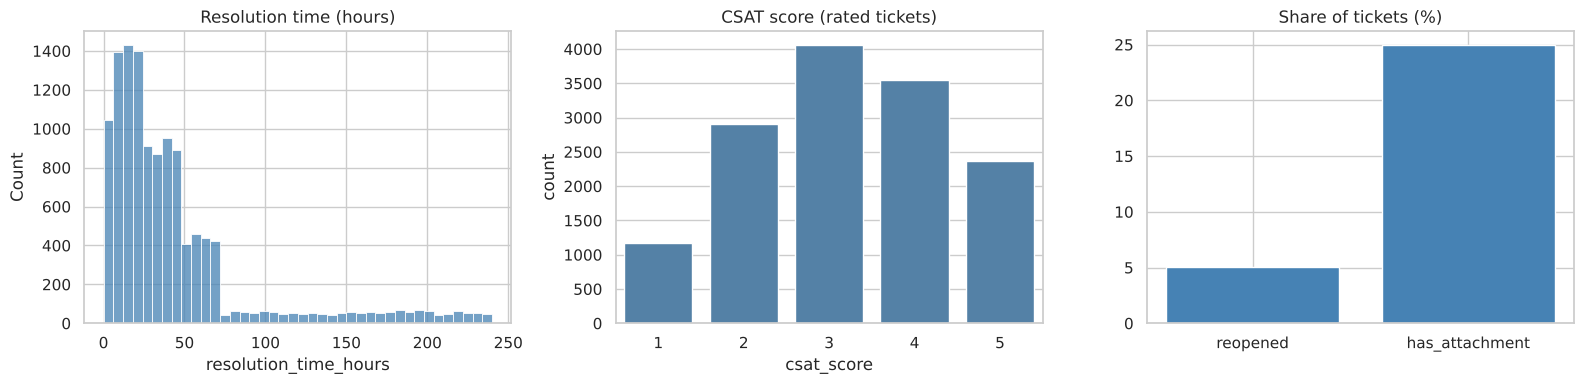

,count,mean,std,min,25%,50%,75%,max
resolution_time_hours,12160.00,44.66,49.21,0.11,14.47,29.48,51.02,239.94
csat_score,14056.00,3.22,1.19,1.00,2.00,3.00,4.00,5.00
reopened,20000.00,0.05,0.22,0.00,0.00,0.00,0.00,1.00
has_attachment,20000.00,0.25,0.43,0.00,0.00,0.00,0.00,1.00


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(clean["resolution_time_hours"].dropna(), bins=40, color="steelblue", ax=axes[0])
axes[0].set_title("Resolution time (hours)")

sns.countplot(x=clean["csat_score"].dropna().astype(int), color="steelblue", ax=axes[1])
axes[1].set_title("CSAT score (rated tickets)")

shares = clean[["reopened", "has_attachment"]].mean() * 100
axes[2].bar(shares.index, shares.values, color="steelblue")
axes[2].set_title("Share of tickets (%)")

plt.tight_layout(); plt.savefig(f"{OUT_DIR}/03_numeric.png"); plt.show()
clean[["resolution_time_hours", "csat_score", "reopened", "has_attachment"]].describe().T

IQR upper limit: 105.9 hours | tickets above it: 1228

Status of those tickets:
status
closed_no_action    1228


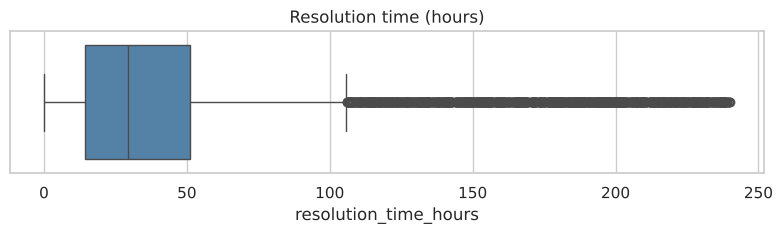

In [23]:
# outliers in resolution time with the IQR rule
rt = clean["resolution_time_hours"].dropna()
q1, q3 = rt.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"IQR upper limit: {upper:.1f} hours | tickets above it: {(rt > upper).sum()}")
print("\nStatus of those tickets:")
print(clean.loc[clean["resolution_time_hours"] > upper, "status"].value_counts().to_string())

plt.figure(figsize=(8, 2.5))
sns.boxplot(x=rt, color="steelblue")
plt.title("Resolution time (hours)")
plt.tight_layout(); plt.show()

Resolution time has a long right tail. Every ticket above the IQR limit (about 106 hours) is a "closed_no_action" ticket,
meaning it was closed after the customer stopped replying. These aren't errors, they just measure something different
from a real fix. We keep them, and when we talk about how long fixes take we'll look at resolved tickets only.

About 5% of tickets get reopened and a quarter come with an attachment.

### 4.4 Message text

count   20000.00
mean       10.22
std         1.79
min         8.00
25%         9.00
50%         9.00
75%        12.00
max        14.00


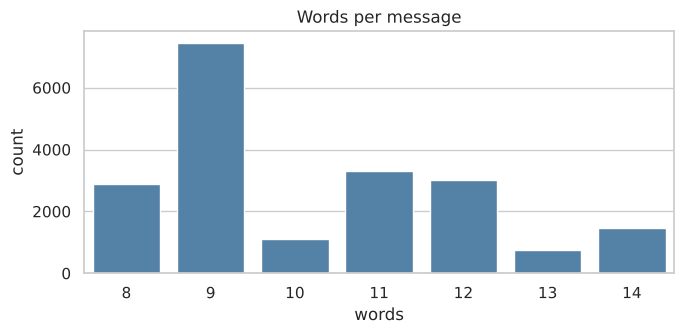

,tickets
initial_message,
My account was locked after multiple failed login attempts.,863
"Something seems off, can you please check my workspace?",848
I downgraded my plan but I am still being billed for the higher tier.,841
I have a general question about my account.,833
We need details about your data encryption and compliance.,832
I cannot log in; the system says my password is incorrect.,830
I noticed a suspicious login on my account.,829
My 2FA code is not working when I try to sign in.,829
I was charged twice for my subscription this month.,821


In [24]:
print(clean["word_count"].describe().to_string())

plt.figure(figsize=(7, 3.5))
sns.countplot(x=clean["word_count"], color="steelblue")
plt.title("Words per message"); plt.xlabel("words")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/04_word_count.png"); plt.show()

clean[TEXT].value_counts().head(10).to_frame("tickets")

Messages are short, between 8 and 14 words. The most common sentences are generic ones ("I cannot log in...",
"I was charged twice...") repeated around 4,000 times each. Sentences that name a product
("The billing page is very slow...") appear about 600 times each.

### 4.5 Dates

Tickets per month: average 417, lowest 350, highest 473


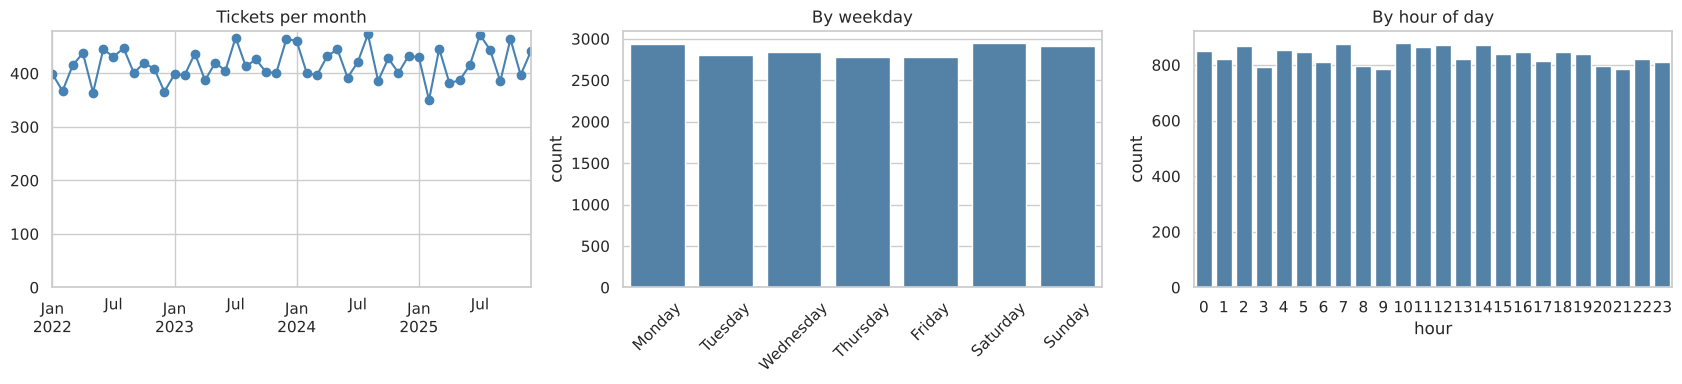

In [25]:
monthly = clean.groupby("month").size()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
monthly.plot(ax=axes[0], marker="o", color="steelblue")
axes[0].set_ylim(0, None); axes[0].set_title("Tickets per month"); axes[0].set_xlabel("")

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.countplot(x=clean["weekday"], order=days, color="steelblue", ax=axes[1])
axes[1].set_title("By weekday"); axes[1].tick_params(axis="x", rotation=45); axes[1].set_xlabel("")

sns.countplot(x=clean["hour"], color="steelblue", ax=axes[2])
axes[2].set_title("By hour of day")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_dates.png"); plt.show()

print(f"Tickets per month: average {monthly.mean():.0f}, lowest {monthly.min()}, highest {monthly.max()}")

Volume is flat from 2022 to 2025, at around 420 tickets a month in our sample. There's no busy weekday, no busy hour and no season.
Real helpdesks are much busier on weekday mornings, so this again points to synthetic timestamps.

## 5. Class imbalance

If one category had far more tickets than the others, a model could get a high accuracy just by predicting that
category most of the time, while doing badly on the small ones. So we check how even the classes are.

Largest class : how_to 2548
Smallest class: bug 2470
Imbalance ratio (largest / smallest): 1.03
Accuracy if we always guess the largest class: 12.7%


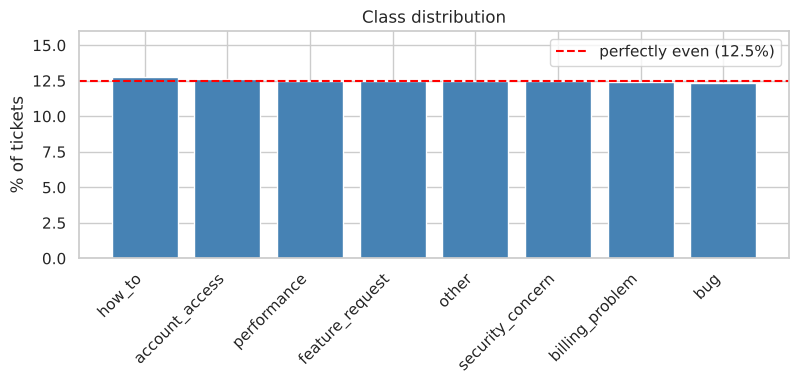

In [26]:
counts = clean[TARGET].value_counts()
print("Largest class :", counts.idxmax(), counts.max())
print("Smallest class:", counts.idxmin(), counts.min())
print(f"Imbalance ratio (largest / smallest): {counts.max() / counts.min():.2f}")
print(f"Accuracy if we always guess the largest class: {counts.max() / len(clean):.1%}")

plt.figure(figsize=(8, 4))
plt.bar(counts.index, counts / len(clean) * 100, color="steelblue")
plt.axhline(100 / len(counts), color="red", ls="--", label="perfectly even (12.5%)")
plt.ylim(0, 16); plt.ylabel("% of tickets"); plt.xticks(rotation=45, ha="right")
plt.legend(loc="upper right"); plt.title("Class distribution")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/06_class_balance.png"); plt.show()

The classes are balanced. The biggest is only 1.03 times the smallest, and always guessing the biggest class
would give just 12.7% accuracy. So we don't need oversampling, SMOTE or class weights.
We'll still report macro F1 (every class counts equally) along with weighted F1, as the brief asks.

There is a less obvious imbalance though: how many *different* sentences each class has.

In [27]:
clean.groupby(TARGET)[TEXT].nunique().sort_values().to_frame("different messages")

,different messages
issue_type,
account_access,3
billing_problem,3
other,3
security_concern,9
performance,15
bug,21
feature_request,21
how_to,21


account_access, billing_problem and other each have only 3 different sentences, while bug, feature_request and how_to have 21.
The ticket counts are even, but the variety of wording isn't. A model gets very few examples of how people describe
the 3-sentence classes, so these are the ones most likely to fail on new wording. We'll treat them as the "minority"
classes to watch during evaluation.

## 6. Bivariate analysis

Now we look at two columns together. The main question is which columns are related to the target.

The tools:
- **Crosstab**: a table of counts or percentages for two categorical columns
- **Chi-square test**: tells us whether two categorical columns are related at all (p below 0.05 means related)
- **Cramér's V**: tells us how strong that relationship is, from 0 (none) to 1 (perfect)
- **Kruskal-Wallis test**: tells us whether a numeric column differs between groups (p below 0.05 means it does)

### 6.1 Target vs every categorical column

In [28]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, dof, expected = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return p, v

rows = []
for col in ["priority", "channel", "product_area", "platform", "region", "customer_segment",
            "sla_plan", "has_attachment", "weekday", "status", "customer_sentiment", "reopened"]:
    p, v = cramers_v(clean[col], clean[TARGET])
    rows.append({"column": col, "p_value": round(p, 4), "cramers_v": round(v, 3),
                 "related": "yes" if p < 0.05 and v >= 0.1 else "no"})

pd.DataFrame(rows).sort_values("cramers_v", ascending=False)

,column,p_value,cramers_v,related
10,customer_sentiment,0.00,0.19,yes
0,priority,0.19,0.02,no
5,customer_segment,0.20,0.02,no
2,product_area,0.12,0.02,no
8,weekday,0.29,0.02,no
11,reopened,0.32,0.02,no
3,platform,0.49,0.02,no
1,channel,0.39,0.02,no
6,sla_plan,0.46,0.02,no
9,status,0.74,0.02,no


In [29]:
# for example: the priority mix is the same in every category
pd.crosstab(clean[TARGET], clean["priority"], normalize="index").mul(100).round(1)

priority,high,low,medium,urgent
issue_type,,,,
account_access,18.90,38.90,35.80,6.40
billing_problem,19.70,39.30,36.10,4.90
bug,20.20,38.20,37.10,4.50
feature_request,21.10,36.40,37.10,5.50
how_to,20.60,39.10,35.00,5.30
other,19.80,40.70,34.60,4.90
performance,19.60,40.00,35.60,4.80
security_concern,19.50,39.50,35.80,5.10


Almost nothing is related to the category. Priority, channel, product area, platform, region, segment, SLA plan,
attachments and weekday all have a Cramér's V of 0.02 or less. Every category gets the same mix of each.
The one exception is customer sentiment (V about 0.19), but sentiment is only known after the ticket is handled.

So the message text is the only useful input for predicting the category.

### 6.2 Target vs customer experience

In [30]:
experience = clean.groupby(TARGET).agg(
    tickets=("ticket_id", "count"),
    negative_share=("is_negative", "mean"),
    avg_csat=("csat_score", "mean"),
    reopen_rate=("reopened", "mean"),
).sort_values("negative_share", ascending=False)
experience.style.format({"negative_share": "{:.1%}", "avg_csat": "{:.2f}", "reopen_rate": "{:.1%}"})

,tickets,negative_share,avg_csat,reopen_rate
issue_type,,,,
performance,2503,60.8%,2.80,5.4%
security_concern,2492,60.1%,2.85,4.2%
billing_problem,2476,59.1%,2.82,5.4%
account_access,2522,58.1%,2.85,4.8%
bug,2470,30.7%,3.40,4.8%
other,2492,29.0%,3.45,5.4%
feature_request,2497,20.0%,3.73,5.6%
how_to,2548,18.9%,3.76,4.8%


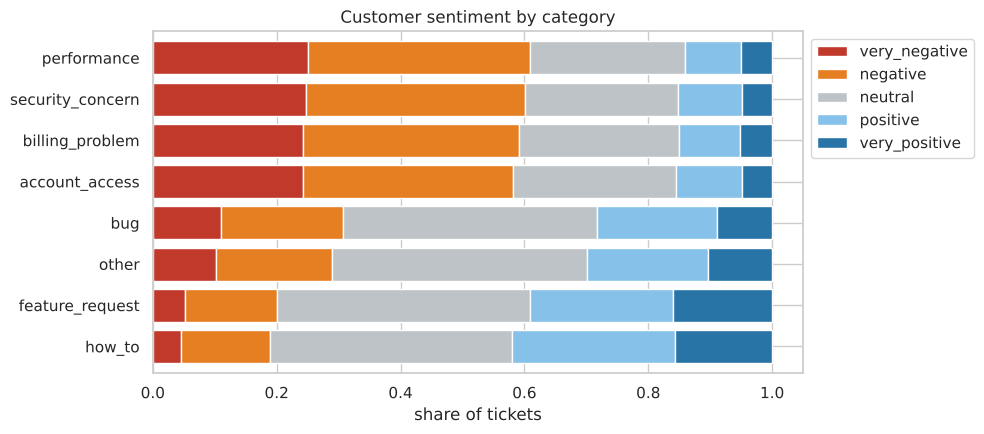

In [31]:
order = ["very_negative", "negative", "neutral", "positive", "very_positive"]
sentiment = pd.crosstab(clean[TARGET], clean["customer_sentiment"], normalize="index")[order]
sentiment = sentiment.loc[experience.index[::-1]]

sentiment.plot.barh(stacked=True, figsize=(10, 4.5), width=0.8,
                    color=["#c0392b", "#e67e22", "#bdc3c7", "#85c1e9", "#2874a6"])
plt.title("Customer sentiment by category"); plt.xlabel("share of tickets"); plt.ylabel("")
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/07_sentiment_by_category.png"); plt.show()

This is the clearest real pattern in the data. Customers raising actual problems are much unhappier:

- security_concern, performance, account_access and billing_problem: about 60% negative, average CSAT around 2.8
- bug and other: about 30% negative, CSAT around 3.4
- how_to and feature_request: about 20% negative, CSAT around 3.7

Reopen rates are about 5% everywhere, so the unhappiness isn't coming from tickets bouncing back.
This is a good insight for the dashboard: the problem categories are where customer satisfaction needs attention.

### 6.3 Target vs resolution time

Kruskal-Wallis p = 0.885
issue_type
account_access     22.40
billing_problem    23.30
bug                23.20
feature_request    23.30
how_to             23.70
other              23.60
performance        22.90
security_concern   22.60


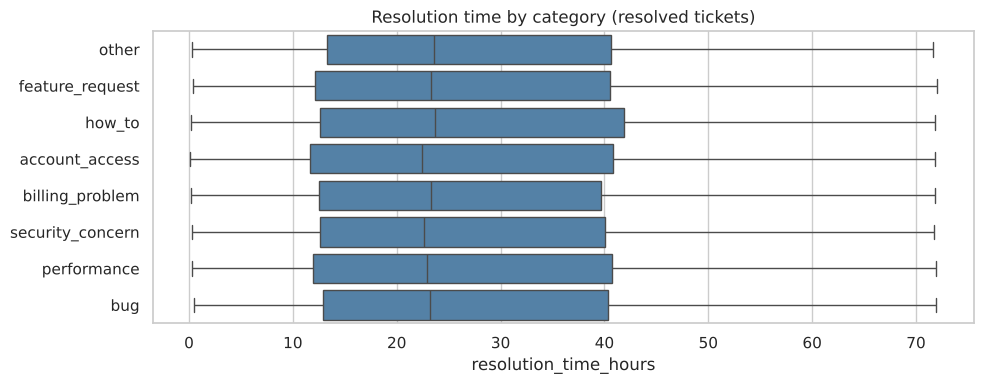

In [32]:
resolved = clean[clean["status"] == "resolved"]

plt.figure(figsize=(10, 4))
sns.boxplot(data=resolved, x="resolution_time_hours", y=TARGET, color="steelblue")
plt.title("Resolution time by category (resolved tickets)"); plt.ylabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/08_resolution_by_category.png"); plt.show()

h, p = stats.kruskal(*[g["resolution_time_hours"] for _, g in resolved.groupby(TARGET)])
print(f"Kruskal-Wallis p = {p:.3f}")
print(resolved.groupby(TARGET)["resolution_time_hours"].median().round(1).to_string())

Every category takes about the same time to resolve (median around 23 hours, Kruskal-Wallis p = 0.89). The category doesn't change how fast a ticket gets fixed.

### 6.4 Priority vs resolution time

          median   max
priority              
urgent      4.05  7.99
high       12.66 24.00
medium     25.53 47.99
low        40.51 71.99


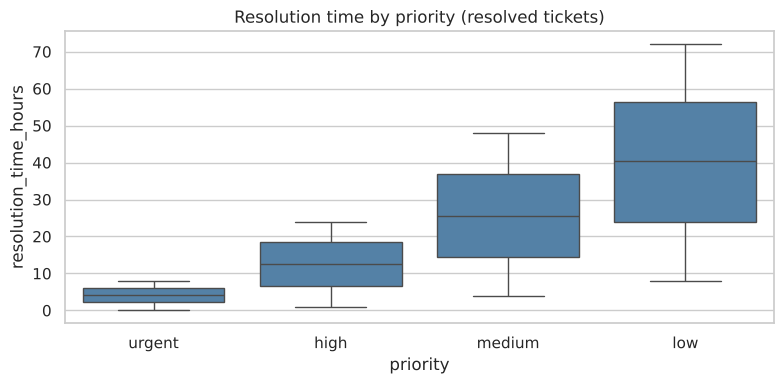

In [33]:
levels = ["urgent", "high", "medium", "low"]

plt.figure(figsize=(8, 4))
sns.boxplot(data=resolved, x="priority", y="resolution_time_hours", order=levels, color="steelblue")
plt.title("Resolution time by priority (resolved tickets)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/09_resolution_by_priority.png"); plt.show()

print(resolved.groupby("priority")["resolution_time_hours"].agg(["median", "max"]).loc[levels])

Priority is what drives resolution time: urgent tickets take about 4 hours, low ones about 40.
Each priority also has a hard ceiling (8, 24, 48 and 72 hours) that no ticket ever goes past, a bit like an SLA limit.
That kind of perfect compliance is another sign of generated data.

### 6.5 Volume over time by category

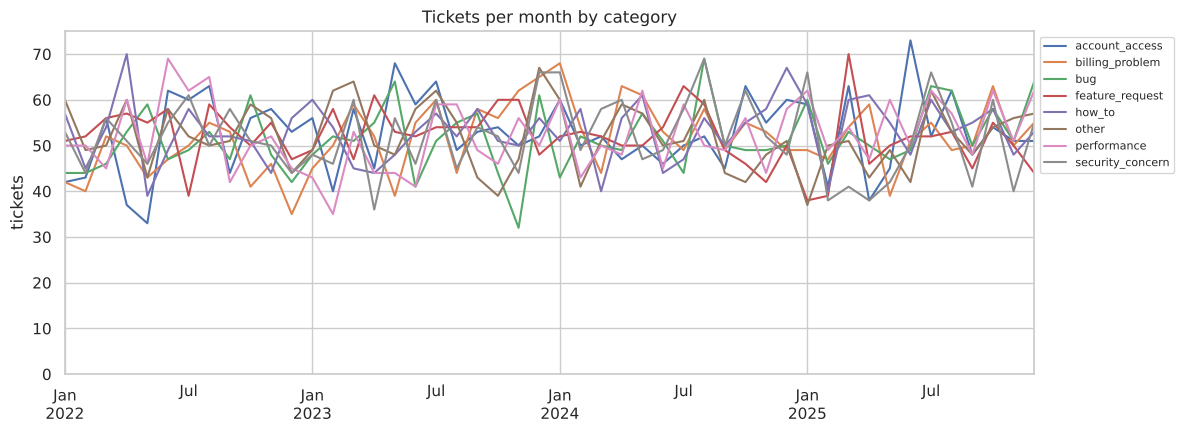

In [34]:
trend = clean.groupby(["month", TARGET]).size().unstack()
trend.plot(figsize=(12, 4.5))
plt.ylim(0, None); plt.title("Tickets per month by category"); plt.xlabel(""); plt.ylabel("tickets")
plt.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/10_trend_by_category.png"); plt.show()

All categories stay flat and close together. No category is growing or fading over the four years.

### 6.6 Message text vs target

In [35]:
labels_per_message = clean.groupby(TEXT)[TARGET].nunique()
print("Messages that appear with more than one category:", (labels_per_message > 1).sum(), "of", len(labels_per_message))

clean.groupby(TEXT)[TARGET].first().sample(8, random_state=1).to_frame("category")

Messages that appear with more than one category: 0 of 96


,category
initial_message,
I was charged twice for my subscription this month.,billing_problem
I need help but I'm not sure which category this fits in.,other
It would be great to have mobile app support in your product.,feature_request
Queries in the analytics dashboard module are timing out.,performance
The mobile app page is very slow and takes a long time to load.,performance
The data export page is very slow and takes a long time to load.,performance
Queries in the notifications module are timing out.,performance
It would be great to have data export support in your product.,feature_request


Every message always comes with the same category, so the text completely decides the label.
That's good news for learning, but it also creates a leakage risk, which section 8 deals with.

## 7. Correlation analysis

Correlation tells us which columns move together. We check it for three kinds of pairs, because each needs a different measure:

| Pair | Measure | Range |
|---|---|---|
| Numeric vs numeric | Pearson (straight-line relationship) and Spearman (any steady up/down relationship) | -1 to 1 |
| Categorical vs categorical | Cramér's V | 0 to 1 |
| Numeric vs categorical | Correlation ratio (eta): how much of the numeric column's spread is explained by the groups | 0 to 1 |

As a rough guide: below 0.1 is no real relationship, 0.1 to 0.3 is weak, 0.3 to 0.5 is moderate, and above 0.5 is strong.

### 7.1 Numeric vs numeric

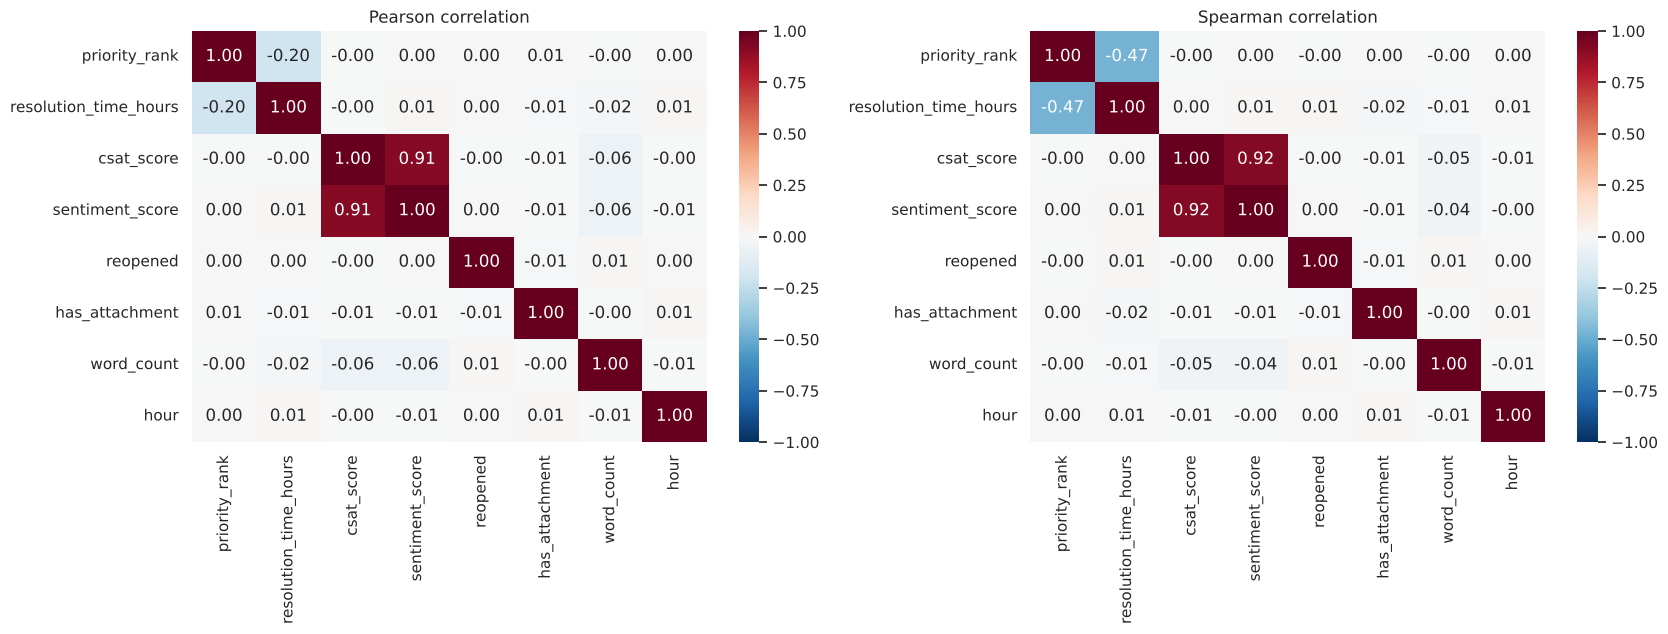

In [36]:
num_cols = ["priority_rank", "resolution_time_hours", "csat_score", "sentiment_score",
            "reopened", "has_attachment", "word_count", "hour"]

pearson = clean[num_cols].corr(method="pearson")
spearman = clean[num_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson correlation")
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman correlation")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/11_numeric_correlation.png"); plt.show()

In [37]:
# list every pair with a correlation of 0.1 or more (each pair once)
pairs = []
for i, a in enumerate(num_cols):
    for b in num_cols[i + 1:]:
        if abs(spearman.loc[a, b]) >= 0.1:
            pairs.append({"column_1": a, "column_2": b,
                          "pearson": round(pearson.loc[a, b], 2), "spearman": round(spearman.loc[a, b], 2)})
pd.DataFrame(pairs).sort_values("spearman", key=abs, ascending=False)

,column_1,column_2,pearson,spearman
1,csat_score,sentiment_score,0.91,0.92
0,priority_rank,resolution_time_hours,-0.20,-0.47


Only two pairs are related; everything else is close to zero.

- **csat_score and sentiment_score** are strongly positive (about 0.9). They measure the same thing, the customer's mood, so in any analysis we should use one of them, not both.
- **priority_rank and resolution_time_hours** are negative: Spearman -0.47, but Pearson only -0.20. Higher priority means faster resolution.
  The gap between the two is a good example of why we check both. Pearson looks for a straight-line relationship and gets pulled
  around by the very long closed_no_action times, while Spearman only looks at the ranking, so it isn't thrown off by those extreme values.

Things that are *not* related are worth noting too: word count, hour of day and attachments have nothing to do with any other column,
and being reopened doesn't affect CSAT.

### 7.2 Categorical vs categorical

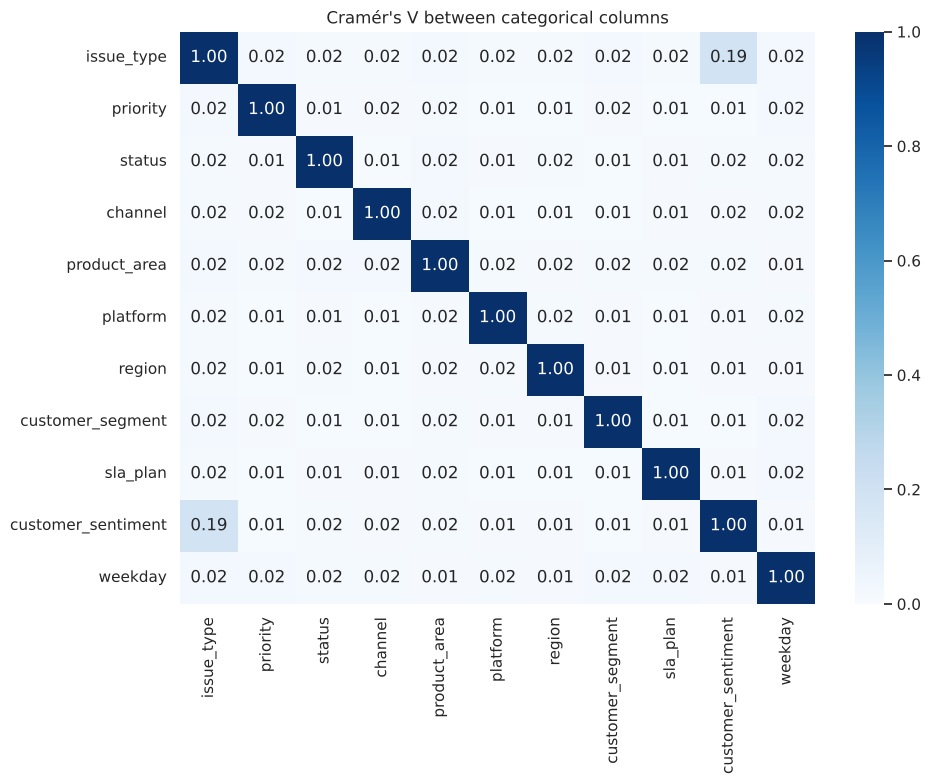

In [38]:
cat_for_corr = [TARGET, "priority", "status", "channel", "product_area", "platform", "region",
                "customer_segment", "sla_plan", "customer_sentiment", "weekday"]

v_matrix = pd.DataFrame(index=cat_for_corr, columns=cat_for_corr, dtype=float)
for a in cat_for_corr:
    for b in cat_for_corr:
        v_matrix.loc[a, b] = 1.0 if a == b else cramers_v(clean[a], clean[b])[1]

plt.figure(figsize=(10, 8))
sns.heatmap(v_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Cramér's V between categorical columns")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/12_categorical_correlation.png"); plt.show()

Almost every value is 0.02 or less. The only notable link is between issue_type and customer_sentiment (around 0.19, weak),
which is the "problem tickets are unhappier" pattern from section 6.2.

This also tells us there is no hidden relationship among the metadata columns themselves
(for example, enterprise customers don't use a particular channel more), so none of them is redundant with another.

### 7.3 Numeric vs categorical

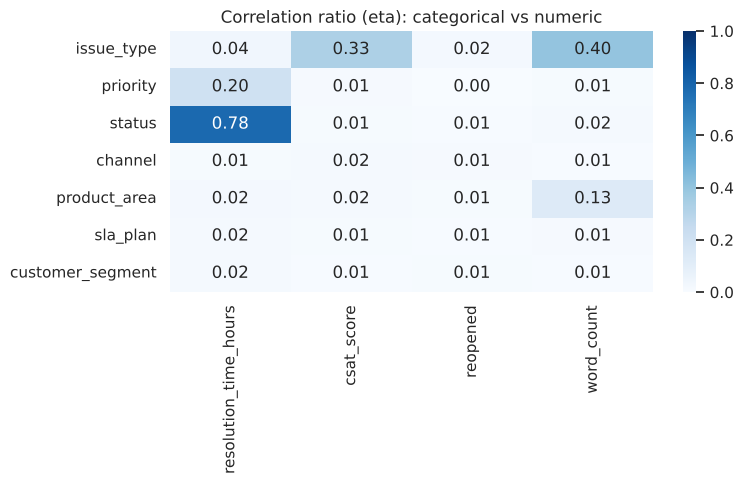

In [39]:
def correlation_ratio(categories, values):
    # eta: share of the spread in 'values' explained by the groups in 'categories' (0 to 1)
    data = pd.DataFrame({"g": categories, "v": values}).dropna()
    overall_mean = data["v"].mean()
    between = data.groupby("g")["v"].apply(lambda s: len(s) * (s.mean() - overall_mean) ** 2).sum()
    total = ((data["v"] - overall_mean) ** 2).sum()
    return np.sqrt(between / total)

numeric_targets = ["resolution_time_hours", "csat_score", "reopened", "word_count"]
group_cols = [TARGET, "priority", "status", "channel", "product_area", "sla_plan", "customer_segment"]

eta = pd.DataFrame(index=group_cols, columns=numeric_targets, dtype=float)
for g in group_cols:
    for v in numeric_targets:
        eta.loc[g, v] = correlation_ratio(clean[g], clean[v])

plt.figure(figsize=(8, 5))
sns.heatmap(eta, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Correlation ratio (eta): categorical vs numeric")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/13_numeric_vs_categorical.png"); plt.show()

A few clear relationships stand out:

- **status and resolution_time_hours** (about 0.8, strong): closed_no_action tickets take far longer than resolved ones, which is what we saw with the outliers.
- **issue_type and word_count** (about 0.4, moderate): each category is written with its own set of sentences, so message length differs by category. This comes from the text itself, which is our input anyway. product_area has a weak link (about 0.13) for the same reason, since product names change sentence length.
- **issue_type and csat_score** (about 0.33, moderate): the "problem tickets are unhappier" pattern again.
- **priority and resolution_time_hours** (about 0.2, weak here): weak only because the long closed_no_action times add a lot of spread. Among resolved tickets alone the effect is much stronger (section 6.4).

Everything else is close to zero.

### 7.4 What the correlation analysis tells us

- The category depends on the **text** and on nothing else that is known when a ticket arrives.
- csat_score and customer_sentiment are basically the same information; keep one in any analysis.
- Resolution time is explained by priority and status, not by category.
- There's no multicollinearity to worry about among the arrival columns, because they are all independent of each other.

## 8. Data leakage

Data leakage is when a model gets information during training that it wouldn't have when predicting a real new ticket.
The test scores then look great, but the model falls apart in real use. We check three ways this could happen here.

### 8.1 Columns that give away the answer

`agent_first_reply` and `resolution_summary` are written by the agent *after* they've read and categorised the ticket.

In [40]:
reply_start = clean["agent_first_reply"].str.split(".").str[0]
pd.crosstab(reply_start, clean[TARGET])

issue_type,account_access,billing_problem,bug,feature_request,how_to,other,performance,security_concern
agent_first_reply,,,,,,,,
Happy to help with your question,0,0,0,0,2548,0,0,0
Sorry to hear you're having trouble accessing your account,2522,0,0,0,0,0,0,0
Thanks for contacting support,0,0,0,0,0,2492,0,0
Thanks for reaching out about the billing issue,0,2476,0,0,0,0,0,0
Thanks for reporting this bug,0,0,2470,0,0,0,0,0
Thanks for your feature suggestion,0,0,0,2497,0,0,0,0
We take security very seriously,0,0,0,0,0,0,0,2492
We understand performance issues can be frustrating,0,0,0,0,0,0,2503,0


In [41]:
pd.crosstab(clean["resolution_summary"].fillna("(not resolved yet)"), clean[TARGET])

issue_type,account_access,billing_problem,bug,feature_request,how_to,other,performance,security_concern
resolution_summary,,,,,,,,
(not resolved yet),1003,977,950,983,990,981,961,995
Adjusted the invoice and issued a refund where applicable.,0,1263,0,0,0,0,0,0
Captured the request and added it to the product backlog.,0,0,0,1247,0,0,0,0
"Investigated logs, mitigated the issue, and updated security settings.",0,0,0,0,0,0,0,1257
Optimized queries and increased resource allocation.,0,0,0,0,0,0,1295,0
Patched the bug and deployed a fix to production.,0,0,1261,0,0,0,0,0
Provided general guidance and confirmed the issue was resolved.,0,0,0,0,0,1271,0,0
Provided step-by-step instructions and relevant documentation.,0,0,0,0,1263,0,0,0
Reset account credentials and confirmed successful login.,1262,0,0,0,0,0,0,0


Each kind of reply belongs to exactly one category ("Thanks for reporting this bug" is only ever used for bugs),
and the same is true for the resolution summaries, apart from the generic "closed without action" one.
A model that could see these columns would simply read the answer off them, so they can't be used as inputs.

### 8.2 Information from the future

`status`, `resolution_time_hours`, `reopened`, `customer_sentiment` and `csat_score` only exist after the ticket has been handled.
Even though sentiment is somewhat related to category, we can't use it: when a new ticket comes in, nobody knows yet how the customer will feel.

### 8.3 The same message in training and testing

There are only 96 different messages. If we split tickets randomly into train and test, the same sentences end up on both sides.
The test would then only check whether the model *remembers* sentences it has already seen, not whether it can handle new ones.
Let's compare a random split with a split by message.

In [42]:
# Option A: random split of tickets
train_a, test_a = train_test_split(clean, test_size=0.2, random_state=42, stratify=clean[TARGET])
overlap_a = test_a[TEXT].isin(set(train_a[TEXT])).mean()

# Option B: split the 96 messages, then put every ticket with a test message into the test set
messages = clean[[TEXT, TARGET]].drop_duplicates()
train_msgs, test_msgs = train_test_split(messages, test_size=0.2, random_state=42, stratify=messages[TARGET])
train_b = clean[clean[TEXT].isin(train_msgs[TEXT])]
test_b = clean[clean[TEXT].isin(test_msgs[TEXT])]
overlap_b = test_b[TEXT].isin(set(train_b[TEXT])).mean()

print(f"Random split   : {overlap_a:.1%} of test tickets have a message already seen in training")
print(f"Split by message: {overlap_b:.1%} of test tickets have a message already seen in training")
print(f"\nSplit by message -> train {len(train_b):,} tickets ({len(train_msgs)} messages), "
      f"test {len(test_b):,} tickets ({len(test_msgs)} messages)")
print("\nTest tickets per category:")
print(test_b[TARGET].value_counts().to_string())

Random split   : 100.0% of test tickets have a message already seen in training
Split by message: 0.0% of test tickets have a message already seen in training

Split by message -> train 15,477 tickets (76 messages), test 4,523 tickets (20 messages)

Test tickets per category:
issue_type
account_access      863
billing_problem     841
other               811
how_to              495
bug                 485
feature_request     461
performance         346
security_concern    221


With a random split, every single test message was already in the training data, so any model would look close to perfect.
That score would be misleading. Splitting by message brings the overlap down to zero, and the test then measures
what we actually care about: how the model handles wording it hasn't seen.

So for modelling we'll **split by message**. One side effect: the test set ends up with uneven class sizes
(see the test counts per category above), and the 3-sentence classes are tested on a single sentence.
That's why we should look at per-class precision, recall and F1, not just overall accuracy.

### 8.4 Leakage summary

In [43]:
leakage = pd.DataFrame([
    ["initial_message", "Known when the ticket arrives", "No", "Use as model input"],
    ["agent_first_reply", "Written after categorising; one reply type per category", "Yes", "Drop"],
    ["resolution_summary", "Written after resolving; one summary per category", "Yes", "Drop"],
    ["status, resolution_time_hours, reopened", "Only known later", "Yes", "Drop from model, use in dashboard"],
    ["customer_sentiment, csat_score", "Only known later", "Yes", "Drop from model, use in dashboard"],
    ["priority, channel, product_area, platform, region, segment, sla_plan, has_attachment",
     "Known at arrival but unrelated to category", "No", "Not needed"],
    ["ticket_id, customer_id", "Identifiers", "No", "Drop"],
    ["Repeated messages", "Same sentences in train and test", "Yes", "Split by message"],
], columns=["column / issue", "reason", "leakage?", "decision"])
leakage

,column / issue,reason,leakage?,decision
0,initial_message,Known when the ticket arrives,No,Use as model input
1,agent_first_reply,Written after categorising; one reply type per category,Yes,Drop
2,resolution_summary,Written after resolving; one summary per category,Yes,Drop
3,"status, resolution_time_hours, reopened",Only known later,Yes,"Drop from model, use in dashboard"
4,"customer_sentiment, csat_score",Only known later,Yes,"Drop from model, use in dashboard"
5,"priority, channel, product_area, platform, region, segment, sla_plan, has_attachment",Known at arrival but unrelated to category,No,Not needed
6,"ticket_id, customer_id",Identifiers,No,Drop
7,Repeated messages,Same sentences in train and test,Yes,Split by message


## 9. Summary

In [44]:
clean.to_csv(config.PROCESSED / "tickets_clean.csv", index=False)
print("Saved data/processed/tickets_clean.csv:", clean.shape)
print("Charts:", sorted(f for f in os.listdir(OUT_DIR) if f.endswith(".png")))

Saved data/processed/tickets_clean.csv: (20000, 27)
Charts: ['01_target.png', '02_categorical.png', '03_numeric.png', '04_word_count.png', '05_dates.png', '06_class_balance.png', '07_sentiment_by_category.png', '08_resolution_by_category.png', '09_resolution_by_priority.png', '10_trend_by_category.png', '11_numeric_correlation.png', '12_categorical_correlation.png', '13_numeric_vs_categorical.png']


| Area | What we found | What we'll do |
|---|---|---|
| Quality | No duplicates, empty texts or impossible values | Light cleaning only |
| Missing values | Resolution fields empty only for unfinished tickets; region missing at random | Leave resolution empty; region as "Unknown" |
| Invalid values | csat_score = 0 means "not rated" | Treat as missing |
| Univariate | Even spreads, short messages, flat volume over time | Data is synthetic; say so in the report |
| Outliers | Long resolution times are all closed_no_action tickets | Keep them; use resolved tickets for fix times |
| Class balance | Balanced (ratio 1.03), but 3 classes have only 3 sentences each | No resampling; watch those 3 classes; use macro F1 |
| Bivariate | Arrival details are unrelated to category; the text decides it | Use the text only |
| Bivariate | Problem categories ~60% negative vs ~20% for requests; fix time depends on priority | Main insights for the dashboard |
| Correlation | csat and sentiment carry the same information; priority drives resolution time; arrival columns are independent | Keep one of csat/sentiment; no multicollinearity issue |
| Leakage | Agent reply and resolution summary give away the label; outcome columns are from the future | Exclude from model inputs |
| Leakage | Random split puts every test message in training | Split by message |

Saved: `data/processed/tickets_clean.csv` (used by every later notebook and the dashboard) and all charts in `reports/figures/`.

Next, notebook 02: split by message, start with a simple baseline, then compare Logistic Regression, SVM and Naive Bayes on TF-IDF features,
using per-class precision, recall and F1, macro and weighted F1, ROC-AUC and a confusion matrix.